# 01 · Geometry and similarity

## The engineering question
When do dot product, cosine similarity, and Euclidean distance produce different neighbors?

**Learning outcomes:** compute the scores by hand; explain the effect of vector magnitude; recognize undefined cosine for zero vectors; connect metric choice to model training.

For vectors $q$ and $x$, the dot product is $q^T x$, cosine is $q^T x/(\|q\|\|x\|)$, and Euclidean distance is $\|q-x\|_2$. Larger dot/cosine scores rank first; smaller distances rank first. With unit vectors, squared Euclidean distance equals $2-2\cos(q,x)$, so their ordering agrees. Without normalization, it need not.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("01", "T", docker=False)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


,candidate,dot,cosine,euclidean
0,exact direction,1.0,1.000000,0.000000
1,large magnitude,3.0,0.948683,2.236068
2,orthogonal,0.0,0.000000,1.414214
3,opposite,-1.0,-1.000000,2.000000


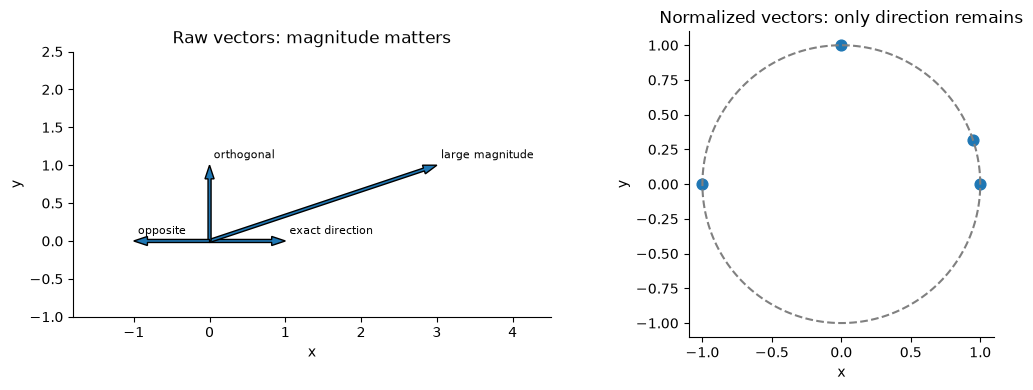

In [2]:
query = np.array([1.0, 0.0])
vectors = np.array([[1.0, 0.0], [3.0, 1.0], [0.0, 1.0], [-1.0, 0.0]])
names = ["exact direction", "large magnitude", "orthogonal", "opposite"]
dots = vectors @ query
cosine = dots / (np.linalg.norm(vectors, axis=1) * np.linalg.norm(query))
distances = np.linalg.norm(vectors - query, axis=1)
results = lesson.table(
    pd.DataFrame({"candidate": names, "dot": dots, "cosine": cosine, "euclidean": distances})
)
display(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for v, name in zip(vectors, names):
    axes[0].arrow(0, 0, *v, width=0.04, length_includes_head=True)
    axes[0].annotate(name, v, xytext=(3, 5), textcoords="offset points", fontsize=8)
axes[0].set(
    xlim=(-1.8, 4.5), ylim=(-1, 2.5), title="Raw vectors: magnitude matters", xlabel="x", ylabel="y"
)
axes[0].set_aspect("equal", adjustable="box")
unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
axes[1].scatter(unit[:, 0], unit[:, 1], s=60)
theta = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(theta), np.sin(theta), "--", color="gray")
axes[1].set_aspect("equal")
axes[1].set(title="Normalized vectors: only direction remains", xlabel="x", ylabel="y")
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Deliberate failure
The large-magnitude vector wins on dot product despite differing from the query direction. Neither metric is universally correct: a trained model may intentionally encode information in magnitude. The index metric must match the representation's intended use.

**Exercise:** replace the second candidate with `[0.8, 0.1]`. Predict all three rankings, then verify. Explain why a zero vector cannot have a meaningful cosine angle.

Use this hand-built geometry to verify formulas and indexing conventions. It does not model the semantic geometry of a language encoder, and a two-dimensional projection of a real encoder is not evidence of retrieval quality.

In [3]:
from vector_masterclass.retrieval import normalized

zero_rejected = False
try:
    normalized(np.array([0.0, 0.0]))
except ValueError:
    zero_rejected = True
unit_dist2 = np.sum((unit - query) ** 2, axis=1)
manifest = lesson.finish(
    {
        "dot_favors_magnitude": int(dots.argmax()) == 1,
        "cosine_favors_exact_direction": int(cosine.argmax()) == 0,
        "normalized_metric_identity": bool(np.allclose(unit_dist2, 2 - 2 * cosine)),
        "zero_vector_rejected": zero_rejected,
    }
)

{
  "artifact": "artifacts/20261031T042953Z-85077f/01",
  "checks": {
    "dot_favors_magnitude": true,
    "cosine_favors_exact_direction": true,
    "normalized_metric_identity": true,
    "zero_vector_rejected": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.